In [1]:
import pandas as pd
import matplotlib.pyplot as plt

r = pd.read_csv("zomato_clean_restaurants.csv")

**1.Top 10 areas by restaurant count**

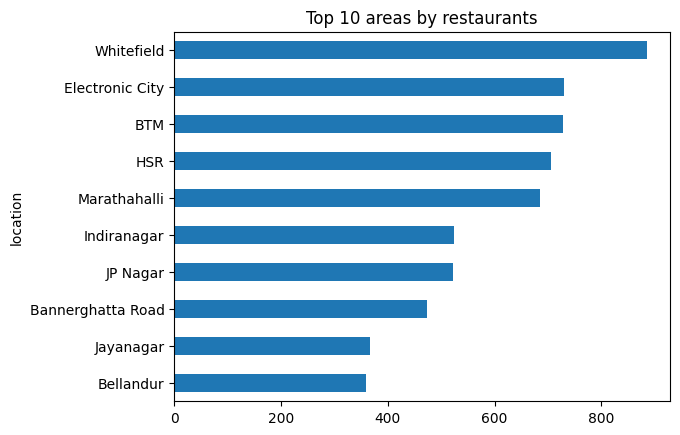

In [2]:
r["location"].value_counts().head(10).plot(kind="barh", title="Top 10 areas by restaurants")
plt.gca().invert_yaxis()
plt.show()

**2.Average rating by area (reliable ratings only)**

In [3]:
reliable = r[r["votes"] >= 50]
(reliable.groupby("location")["rating"]
 .agg(["mean", "count"])
 .query("count >= 10")
 .sort_values("mean", ascending=False)
 .head(10))

,mean,count
location,,
Lavelle Road,4.132609,46
Koramangala 5th Block,4.123214,168
Race Course Road,4.100000,18
Residency Road,4.071739,46
Koramangala 3rd Block,4.050000,14
Seshadripuram,4.044000,25
St. Marks Road,4.042857,28
Richmond Road,4.032432,37
Sadashiv Nagar,4.017647,17


**3.Rating distribution**

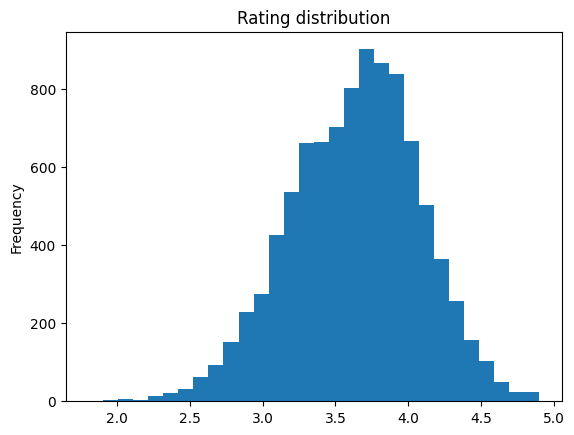

In [4]:
r["rating"].plot(kind="hist", bins=30, title="Rating distribution")
plt.show()

**4.Cost by restaurant type**

In [5]:
(r.groupby("primary_rest_type")["cost_for_two"]
 .agg(["count", "mean"])
 .sort_values("count", ascending=False)
 .head(10))

,count,mean
primary_rest_type,,
Quick Bites,5128,311.911076
Casual Dining,2423,789.331407
Delivery,923,435.275190
Takeaway,788,375.734772
Dessert Parlor,644,329.798137
Cafe,615,615.934959
Bakery,449,380.668151
Beverage Shop,381,246.797900
Food Court,221,434.751131


**5.Online order vs rating**

In [6]:
reliable.groupby("online_order")["rating"].agg(["mean", "count"])

,mean,count
online_order,,
False,3.879093,1478
True,3.788671,3363


**6.Correlation**

In [7]:
r[["rating", "votes", "cost_for_two", "cuisine_count"]].corr()

,rating,votes,cost_for_two,cuisine_count
rating,1.000000,0.397031,0.326047,0.140626
votes,0.397031,1.000000,0.354412,0.204118
cost_for_two,0.326047,0.354412,1.000000,0.249755
cuisine_count,0.140626,0.204118,0.249755,1.000000
